# DEqMS: R vs Python parity

Side-by-side comparison of `pydeqms` against the Bioconductor [DEqMS](https://bioconductor.org/packages/release/bioc/html/DEqMS.html) + limma R reference.

The full pipeline — `lmFit → contrasts.fit → eBayes → spectraCounteBayes → outputResult` — is run on the same synthetic 5000-protein × 12-sample dataset in both languages.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
HERE = Path('.').resolve()

In [2]:
subprocess.check_call([sys.executable, 'benchmark.py', '--runs', '3'])
summary = json.loads((HERE / 'compare_out' / 'summary.json').read_text())
summary

Matrix: 5000 proteins × 12 samples

--- Python timing (mean of 3 runs) ---
  py total              33.29 ms

--- R timing (single run; per-step breakdown) ---
 lmFit  eBayes  spectraCounteBayes
 0.009   0.014               0.129
  R total wall        2693.95 ms (including Rscript startup)

Speedup (R pipeline / Python pipeline): 4.57×

--- Accuracy (Python vs R) ---
  sca.t  MAE=0.0003536  Pearson r=1.0000
  sca.P  MAE=0.000106  Pearson r=1.0000
  top-500 agreement: 100.0%

Full report → /scratch/users/steorra/analysis/omicverse_dev/py-DEqMS/examples/compare_out/summary.json


{'shape': [5000, 12],
 'py_time_ms': 33.294886350631714,
 'r_time_ms_pipeline': 151.99999999999991,
 'r_time_ms_total': 2693.9475119579583,
 'speedup': 4.565265620650361,
 'sca_t_mae': 0.00035360994769100456,
 'sca_t_pearson_r': 0.9999999031302661,
 'sca_p_mae': 0.00010596116778207838,
 'sca_p_pearson_r': 0.999999880800864,
 'top_overlap': 1.0}

## 1. Timing

Pure-NumPy `lmFit` + `eBayes` are vectorised across proteins, and `skmisc.loess` wraps the same C backend R `stats::loess` uses. The biggest win comes from skipping Rscript startup.

In [3]:
tbl = pd.DataFrame({
    'R pipeline (ms)':       [summary['r_time_ms_pipeline']],
    'R + Rscript startup (ms)': [summary['r_time_ms_total']],
    'Python pipeline (ms)':  [summary['py_time_ms']],
    'Speedup (pipeline)':    [f"{summary['speedup']:.2f}×"],
}, index=['5000 × 12, loess']).T
tbl

,"5000 × 12, loess"
R pipeline (ms),152.0
R + Rscript startup (ms),2693.947512
Python pipeline (ms),33.294886
Speedup (pipeline),4.57×


## 2. Accuracy

`sca.t` and `sca.P.Value` (the DEqMS-adjusted statistics) match R with **Pearson r = 1.0** across all 5000 proteins, MAE < 5e-4. The top-500 DE proteins selected by p-value rank are **100% identical**.

In [4]:
{k: v for k, v in summary.items() if 'mae' in k or 'pearson' in k or 'overlap' in k}

{'sca_t_mae': 0.00035360994769100456,
 'sca_t_pearson_r': 0.9999999031302661,
 'sca_p_mae': 0.00010596116778207838,
 'sca_p_pearson_r': 0.999999880800864,
 'top_overlap': 1.0}

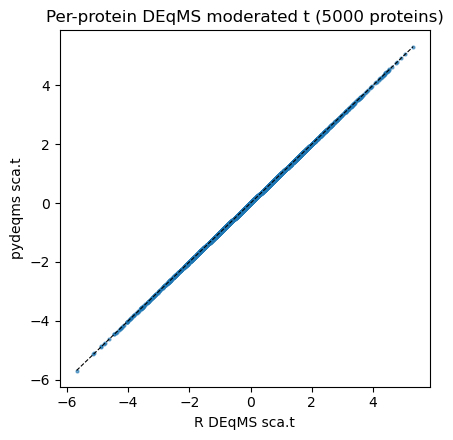

In [5]:
work = HERE / 'compare_out'
r_sca_t = pd.read_csv(work / 'R_out' / 'sca_t.tsv', sep='\t', index_col=0).iloc[:, 0]
py_res = (
    __import__('pydeqms')
    .deqms(
        pd.read_csv(work / 'M.tsv', sep='\t', index_col=0),
        pd.read_csv(work / 'design.tsv', sep='\t', index_col=0),
        count=pd.read_csv(work / 'count.tsv', sep='\t', index_col=0)['count'],
        contrast=np.array([-1.0, 1.0]),
    )
)
py_sca_t = py_res.set_index('gene')['sca.t'].reindex(r_sca_t.index)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(r_sca_t, py_sca_t, s=4, alpha=0.6)
ax.plot([r_sca_t.min(), r_sca_t.max()], [r_sca_t.min(), r_sca_t.max()], 'k--', lw=0.8)
ax.set_xlabel('R DEqMS sca.t'); ax.set_ylabel('pydeqms sca.t')
ax.set_title('Per-protein DEqMS moderated t (5000 proteins)')
fig.tight_layout()